<a href="https://colab.research.google.com/github/FranciscoLopez27/acif104-brotes-eta/blob/main/notebooks/04_calibracion_y_modelo_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Preparación

In [4]:
import sys, os
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("acif104-brotes-eta").exists():
        !git clone https://github.com/FranciscoLopez27/acif104-brotes-eta.git
    os.chdir("acif104-brotes-eta")
    !git pull -q
    !pip -q install imbalanced-learn shap
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())

Cloning into 'acif104-brotes-eta'...
remote: Enumerating objects: 167, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (160/160), done.
remote: Total 167 (delta 47), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (167/167), 6.09 MiB | 8.52 MiB/s, done.
Resolving deltas: 100% (47/47), done.
Carpeta de trabajo: /content/acif104-brotes-eta/acif104-brotes-eta/acif104-brotes-eta


## 2. Datos y función de entrenamiento

In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from src import datos as D, balanceo as B, evaluacion as E, modelos_ml as ML
from src.calibracion import Calibrador, error_calibracion
from src.config import CAT, NUM, AZUL, NARANJO, GRIS, VERDE, guardar, guardar_tabla

PARAMS_RF = {"max_depth": None, "min_samples_leaf": 5}
SEMILLA = 42
datos = D.preparar(D.cargar())

def entrenar_rf(part):
  """Entrena el Random Forest con ponderación de clases sobre part['tr'] (igual que en el notebook 03)."""
  cod = D.Codificador().fit(part["tr"][CAT + NUM])
  Mb, yb, w = B.balancear(cod.transform(part["tr"][CAT + NUM]), part["tr"].y.values,
                            "Ponderación de clases", cod, semilla=SEMILLA)
  rf = ML.ajustar(ML.crear_modelo("Random Forest", PARAMS_RF, cod, semilla=SEMILLA), Mb, yb, w)
  return rf, cod

# 3. Predicciones fuera de la muestra (validación cruzada temporal 2019-2022)

In [6]:
t0 = time.time()
p_oof, y_oof, anio_oof = [], [], []
for k in [2019, 2020, 2021, 2022]:
    part_k = D.particionar(datos, fin_entrenamiento=k-1, fin_validacion=k)
    rf_k, cod_k = entrenar_rf(part_k)
    p_oof.append(ML.probabilidad(rf_k, cod_k.transform(part_k["va"][CAT + NUM])))
    y_oof.append(part_k["va"].y.values)
    anio_oof.append(part_k["va"]["Año estadistico"].values)
    print(f"Año {k} listo ({time.time()-t0:.0f} s)")
p_oof, y_oof, anio_oof = map(np.concatenate, (p_oof, y_oof, anio_oof))
print(f"Brotes fuera de muestra: {len(y_oof)} | umbral sin calibrar: {E.umbral_para_recall(y_oof, p_oof):.3f}")

Año 2019 listo (4 s)
Año 2020 listo (9 s)
Año 2021 listo (13 s)
Año 2022 listo (16 s)
Brotes fuera de muestra: 3259 | umbral sin calibrar: 0.397


# 4. Modelo final (2012-2022) y probabilidades en prueba

In [7]:
part_f = D.particionar(datos, fin_entrenamiento=2022, fin_validacion=2022)
rf_f, cod_f = entrenar_rf(part_f)
y_te = part_f["te"].y.values
p_te = ML.probabilidad(rf_f, cod_f.transform(part_f["te"][CAT + NUM]))
print(f"Control, AUC-PR en prueba: {E.metricas(y_te, p_te, 0.5)['AUC-PR']:.3f}")
print(f"Probabilidad media: {p_te.mean():.3f} | proporción real: {y_te.mean():.3f}")

Control, AUC-PR en prueba: 0.499
Probabilidad media: 0.296 | proporción real: 0.177


# 5. Calibración: Platt frente a isotónica

In [8]:
calibradores = {"Platt": Calibrador("platt").fit(p_oof, y_oof),
                "Isotónica": Calibrador("isotonica").fit(p_oof, y_oof)}
prob_te ={"Sin calibrar": p_te, **{n: c.transform(p_te) for n, c in calibradores.items()}}
prob_oof ={"Sin calibrar": p_oof, **{n: c.transform(p_oof) for n, c in calibradores.items()}}

filas=[]
for nombre, p in prob_te.items():
    # umbral recalculado en la nueva escala
    umbral = E.umbral_para_recall(y_oof, prob_oof[nombre], 0.70)
    m = E.metricas(y_te, p, umbral)
    filas.append({"Método": nombre, "AUC-PR": m["AUC-PR"], "Brier": m["Brier"],
                  "ECE": error_calibracion(y_te, p), "Prob. media": p.mean(), "Proporción real": y_te.mean(),
                  "Umbral": umbral, "Recall": m["Recall"], "Precisión": m["Precisión"]})
calib_df = pd.DataFrame(filas)
guardar_tabla(calib_df, "04_calibracion")
# ¿la mejora del Brier es real?
for nombre in calibradores:
    d, lo, hi = E.bootstrap_diferencia(y_te, prob_te["Sin calibrar"], prob_te[nombre], metrica=brier_score_loss)
    print(f"Brier sin calibrar − {nombre}: {d:+.4f} (IC 95%: {lo:+.4f} a {hi:+.4f})")
calib_df.round(3)

Brier sin calibrar − Platt: +0.0146 (IC 95%: +0.0116 a +0.0171)
Brier sin calibrar − Isotónica: +0.0150 (IC 95%: +0.0124 a +0.0174)


,Método,AUC-PR,Brier,ECE,Prob. media,Proporción real,Umbral,Recall,Precisión
0,Sin calibrar,0.499,0.129,0.118,0.296,0.177,0.397,0.715,0.429
1,Platt,0.499,0.114,0.033,0.187,0.177,0.239,0.715,0.429
2,Isotónica,0.475,0.113,0.018,0.188,0.177,0.257,0.795,0.388


# 6. Diagrama de confiabilidad

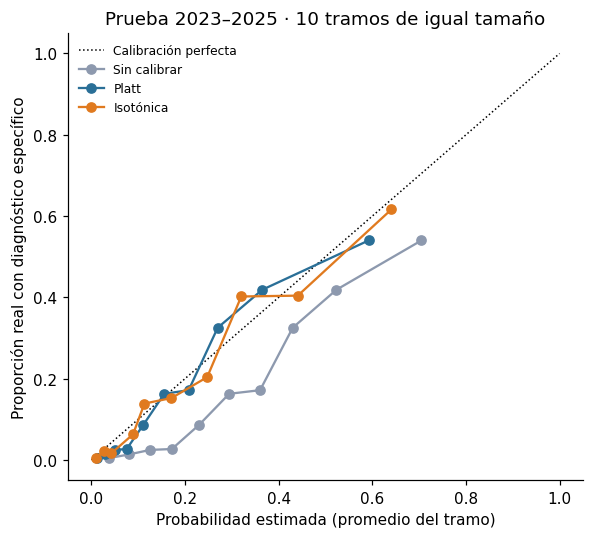

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls=":", color="black", lw=1, label="Calibración perfecta")
for (nombre, p), color in zip(prob_te.items(), [GRIS, AZUL, NARANJO]):
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(media, frac, marker="o", color=color, label=nombre)
ax.set_xlabel("Probabilidad estimada (promedio del tramo)")
ax.set_ylabel("Proporción real con diagnóstico específico")
ax.set_title("Prueba 2023–2025 · 10 tramos de igual tamaño")
ax.legend(frameon=False, fontsize=8)
guardar(fig, "fig_calibracion.png")